# Exercice 2 — Data augmentation par décalage · **version à trous**

**Hands-On ML, chapitre 3, exercice 2** · carnet CS229, bloc **B14**, étape 13 (option)

> *Écrivez une fonction qui décale une image MNIST d'un pixel dans n'importe quelle direction.
> Puis, pour chaque image du training set, créez quatre copies décalées (une par direction) et
> ajoutez-les au training set. Enfin, entraînez votre meilleur modèle sur ce training set étendu
> et mesurez son accuracy sur le test set.*

---

## Comment utiliser ce notebook

Les cellules marquées **`# TODO`** contiennent des `...` à remplacer. Chacune est suivie d'une
**cellule de vérification** avec des `assert` qui vous disent si c'est juste.

Les cellules sans `# TODO` sont complètes : imports, affichage, plomberie. Exécutez-les telles
quelles.

Le corrigé est dans `B14_ex2_data_augmentation.ipynb`.

**7 trous** dans ce notebook. Prérequis : avoir fait l'exercice 1.

## L'idée en une phrase

Le modèle ne sait pas qu'**un 7 décalé d'un pixel reste un 7**. C'est vous qui le savez. La data
augmentation est le canal par lequel vous lui transmettez cette connaissance.

## Pourquoi ça marche, formellement

Vous ne créez **aucune information nouvelle** — les copies décalées sont déterministes. Vous
imposez une **invariance** : vous forcez le modèle à produire la même sortie sur toute une orbite
de transformations.

$$h_{\theta}\left(T(x)\right) = h_{\theta}(x) \quad \text{pour toute translation } T
\text{ d'un pixel}$$

C'est une forme de **régularisation** (bloc **B13**). Au sens de la décomposition du point
**B12-3** :

$$\text{MSE}(x) = \underbrace{\sigma^{2}}_{\text{bruit}} +
\underbrace{\left(h^{*}(x) - h_{\text{avg}}(x)\right)^{2}}_{\text{bias}^{2}} +
\underbrace{\operatorname{var}\left(h_{S}(x)\right)}_{\text{variance}}$$

on attaque le troisième terme.

---
## 1. Environnement

*Cellules complètes.*

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from scipy.ndimage import shift

from sklearn.datasets import fetch_openml
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

SEED = 42
rng = np.random.default_rng(SEED)

plt.rcParams["figure.dpi"] = 110

print("numpy", np.__version__)

numpy 2.3.5


In [2]:
mnist = fetch_openml("mnist_784", as_frame=False, parser="auto")

X = mnist.data.astype(np.uint8)
y = mnist.target.astype(np.uint8)

X_train_full, X_test = X[:60000], X[60000:]
y_train_full, y_test = y[:60000], y[60000:]

print("train complet :", X_train_full.shape)
print("test          :", X_test.shape)

train complet : (60000, 784)
test          : (10000, 784)


---
## 2. Le protocole de comparaison — à lire avant de coder

Cet exercice demande de **comparer deux modèles** : avec et sans augmentation. Donc deux
évaluations.

Or le test set ne se touche **qu'une seule fois** (point **B13-6**). Si on évalue les deux
variantes dessus et qu'on garde la meilleure, on a choisi un hyperparamètre sur le test set : le
score annoncé devient optimiste.

**La solution** : découper le training set en deux.

| Jeu | Taille | Rôle |
|---|---|---|
| `X_train` | 50 000 | Entraînement, avec ou sans augmentation |
| `X_val` | 10 000 | Comparaison des deux variantes |
| `X_test` | 10 000 | Évaluation finale, une seule fois, du gagnant |

C'est la **hold-out cross validation** du point **B13-6**. Plus légère qu'une k-fold ici : un
entraînement sur 250 000 images n'est pas quelque chose qu'on répète cinq fois pour le plaisir.

### Trou 1 — le découpage

In [3]:
# TODO (trou 1) - Decouper X_train_full / y_train_full en deux.
#   Les 50 000 PREMIERES lignes  -> train
#   Les 10 000 DERNIERES         -> validation

X_train, X_val = X_train_full[:50000], X_train_full[50000:]
y_train, y_val = y_train_full[:50000], y_train_full[50000:]

print("train      :", X_train.shape)
print("validation :", X_val.shape)
print("test       :", X_test.shape, " <- on n'y touche qu'a la section 9")

train      : (50000, 784)
validation : (10000, 784)
test       : (10000, 784)  <- on n'y touche qu'a la section 9


In [4]:
# Verification - ne modifiez pas cette cellule
assert X_train.shape == (50000, 784), f"X_train devrait etre (50000, 784), pas {X_train.shape}"
assert X_val.shape == (10000, 784), f"X_val devrait etre (10000, 784), pas {X_val.shape}"
assert len(y_train) == 50000 and len(y_val) == 10000, "les etiquettes ne suivent pas"
assert np.array_equal(X_val[0], X_train_full[50000]), "X_val doit commencer a l'indice 50000"
assert y_val[0] == y_train_full[50000], "X_val et y_val doivent etre decoupes au meme endroit"
print("Trou 1 : OK")

Trou 1 : OK


**Règle absolue** : on augmente **uniquement** `X_train`.

Augmenter la validation ou le test n'aurait aucun sens — on mesurerait la performance sur des
images artificielles, pas sur des chiffres réels. Et augmenter **avant** le split serait un
**data leakage** caractérisé (point **B1M-3**) : la copie décalée d'une image d'entraînement se
retrouverait dans la validation, qui deviendrait un second training set déguisé.

---
## 3. La fonction de décalage

`scipy.ndimage.shift` décale un tableau. Trois points d'attention :

- l'image arrive **aplatie** (784 valeurs) : il faut la remettre en 28 × 28 avant, et l'aplatir
  après ;
- l'ordre des axes est **`[dy, dx]`** — ligne d'abord, colonne ensuite. C'est le piège classique ;
- `cval=0` remplit de noir les pixels qui entrent dans le cadre, `mode="constant"` dit d'utiliser
  cette valeur plutôt que de répéter le bord.

### Trou 2 — `shift_image`

Convention : `dx > 0` décale vers la **droite**, `dy > 0` décale vers le **bas**.

In [5]:
# TODO (trou 2) - Completer l'appel a scipy.ndimage.shift.
#   Entree  : image aplatie (784,), dx et dy entiers
#   Sortie  : image aplatie (784,), decalee
#   Indice  : shift(tableau_2d, [dy, dx], cval=..., mode=...)

def shift_image(image, dx, dy):
    image = image.reshape((28, 28))
    shifted = shift(image, [dy, dx], order=3, mode='constant', cval=0.0, prefilter=True)      
    return shifted.reshape([-1])

In [6]:
# Verification - ne modifiez pas cette cellule
_t = np.zeros((28, 28), dtype=np.uint8)
_t[10, 10] = 255
_plat = _t.reshape(-1)

_r = shift_image(_plat, 1, 0).reshape(28, 28)
assert round(float(_r[10, 11])) == 255, "dx=+1 doit deplacer le pixel vers la DROITE (colonne +1)"
assert round(float(_r[10, 10])) == 0, "la position d'origine doit etre videe"

_r = shift_image(_plat, 0, 1).reshape(28, 28)
assert round(float(_r[11, 10])) == 255, "dy=+1 doit deplacer le pixel vers le BAS (ligne +1)"

_r = shift_image(_plat, -1, 0).reshape(28, 28)
assert round(float(_r[10, 9])) == 255, "dx=-1 doit deplacer vers la GAUCHE"

assert shift_image(_plat, 1, 0).shape == (784,), "la sortie doit etre aplatie (784,)"

_bord = np.zeros((28, 28), dtype=np.uint8)
_bord[0, 0] = 255
assert round(float(shift_image(_bord.reshape(-1), 0, -1).reshape(28, 28).sum())) == 0, \
    "un pixel pousse hors du cadre doit disparaitre"

# Le cadre libere doit etre NOIR (cval=0), pas une copie du bord (mode='nearest')
_col = np.zeros((28, 28), dtype=np.uint8)
_col[:, 0] = 255
assert round(float(shift_image(_col.reshape(-1), 1, 0).reshape(28, 28)[:, 0].max())) == 0, \
    "la colonne liberee doit etre remplie de 0 : utilisez cval=0 ET mode='constant'"
print("Trou 2 : OK")

Trou 2 : OK


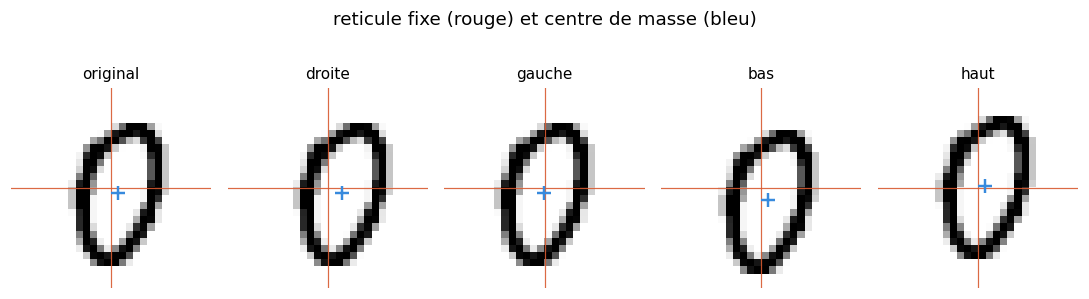

original   dy +0.00  dx +0.00
droite     dy +0.00  dx +1.00
gauche     dy +0.00  dx -1.00
bas        dy +1.00  dx +0.00
haut       dy -1.00  dx +0.00


In [7]:
# Controle visuel - on ne fait jamais confiance a une transformation sans la regarder
from scipy.ndimage import center_of_mass

img = X_train[1000]
directions = [(0, 0, "original"), (1, 0, "droite"), (-1, 0, "gauche"),
              (0, 1, "bas"), (0, -1, "haut")]

fig, axes = plt.subplots(1, 5, figsize=(10, 2.6))
for ax, (dx, dy, nom) in zip(axes, directions):

    #Application du déplacement à une image de référence
    im = shift_image(img, dx, dy).reshape(28, 28)
    ax.imshow(im, cmap="binary")

    # Ajout de lignes de références pour visualisation du déplacement
    ax.axvline(13.5, color="#D85A30", lw=0.8, alpha=0.9)
    ax.axhline(13.5, color="#D85A30", lw=0.8, alpha=0.9)

    cy, cx = center_of_mass(im)
    ax.plot(cx, cy, marker="+", color="#378ADD", ms=9, mew=1.6)

    ax.set_title(nom, fontsize=10)
    ax.axis("off")

fig.suptitle("reticule fixe (rouge) et centre de masse (bleu)", y=1.06)
plt.tight_layout()
plt.show()

ref = center_of_mass(img.reshape(28, 28))
for dx, dy, nom in directions:
    cy, cx = center_of_mass(shift_image(img, dx, dy).reshape(28, 28))
    print(f"{nom:10s} dy {cy-ref[0]:+.2f}  dx {cx-ref[1]:+.2f}")

**Un détail qui mérite d'être mesuré plutôt que supposé.**

Par défaut, `shift` interpole par **spline cubique** (`order=3`). Les splines sont connues pour
**dépasser** l'intervalle des données d'entrée au voisinage d'un bord net : un trait blanc sur
fond noir peut produire des valeurs négatives juste à côté.

Est-ce notre cas ? La cellule suivante mesure, au lieu de supposer. Regardez-la tourner avant de
lire le commentaire qui suit.

In [8]:
for nom, entree in [("uint8  ", X_train[1000]),
                    ("float64", X_train[1000].astype(np.float64))]:
    for dx in [1, 0.5]:
        s = shift_image(entree, dx, 0)
        print(f"entree {nom}  dx={dx:<4} -> dtype {str(s.dtype):8s} "
              f"min {float(s.min()):8.2f}  max {float(s.max()):8.2f}")

entree uint8    dx=1    -> dtype uint8    min     0.00  max   255.00
entree uint8    dx=0.5  -> dtype uint8    min     0.00  max   255.00
entree float64  dx=1    -> dtype float64  min    -0.00  max   255.00
entree float64  dx=0.5  -> dtype float64  min   -21.78  max   296.51


Deux faits, qu'aucune intuition ne donnait :

**À décalage entier, la spline est exacte.** Il n'y a aucune interpolation : les coefficients
valent exactement 0 ou 1, le pixel est recopié tel quel. Aucun dépassement, quel que soit le type
d'entrée. Le dépassement n'apparaît qu'à **décalage fractionnaire** (`dx=0.5`), où il est massif.

**`scipy.ndimage.shift` conserve le type d'entrée.** Avec du `uint8`, scipy écrête lui-même et
vous rend du `uint8` propre, même en fractionnaire.

**Conséquence pour le trou suivant** : le `np.clip(..., 0, 255)` que vous allez écrire est, ici,
un **no-op strict**. Entier + `uint8` : rien à écrêter.

On le garde quand même, et ce n'est pas de la superstition. Dès que vous étendrez l'augmentation
à des **rotations** ou à des décalages **sous-pixel** — ce que fait toute vraie pipeline
d'augmentation — le dépassement devient réel. Et le cast en `uint8` ne sature pas : il **boucle**.

In [9]:
print("sans clip, un 288.6 caste en uint8 ne donne pas 255 mais",
      np.array([288.6]).astype(np.uint8)[0], "<- bouclage silencieux")
print("sans clip, un -42.8 caste en uint8 ne donne pas 0 mais  ",
      np.array([-42.8]).astype(np.uint8)[0])

sans clip, un 288.6 caste en uint8 ne donne pas 255 mais 32 <- bouclage silencieux
sans clip, un -42.8 caste en uint8 ne donne pas 0 mais   214


---
## 4. Construction du training set augmenté

### D'abord, le calcul de mémoire

C'est là que beaucoup de notebooks partent en `MemoryError`. Le training set passe de 50 000 à
250 000 images.

$$250\,000 \times 784 \times 8 \text{ octets} \approx 1{,}6 \text{ Go en float64}$$
$$250\,000 \times 784 \times 1 \text{ octet} \approx 196 \text{ Mo en uint8}$$

Le facteur huit n'est pas cosmétique : il décide si la cellule tourne ou si votre machine se met à
swapper.

*Cellule complète.*

In [10]:
n_aug = 5 * len(X_train)
for dtype, octets in [("float64", 8), ("float32", 4), ("uint8", 1)]:
    print(f"{dtype:8s} : {n_aug * 784 * octets / 1e9:5.2f} Go")

float64  :  1.57 Go
float32  :  0.78 Go
uint8    :  0.20 Go


### Trou 3 — la fonction d'augmentation

On préalloue le tableau de sortie plutôt que d'empiler des listes : plus rapide, et le pic mémoire
est maîtrisé. Le squelette est posé, il reste deux lignes.

Structure du résultat : **bloc 0** = les images originales, **blocs 1 à 4** = une direction
chacun.

In [11]:
DECALAGES = [(1, 0), (-1, 0), (0, 1), (0, -1)]


def augmente(X, y, decalages=DECALAGES):
    n = len(X)
    total = n * (1 + len(decalages))

    X_out = np.empty((total, 784), dtype=np.uint8)
    y_out = np.empty(total, dtype=np.uint8)

    # Bloc 0 : les images originales, inchangees
    X_out[:n] = X
    y_out[:n] = y

    # Blocs 1 a 4 : une direction par bloc
    for k, (dx, dy) in enumerate(decalages, start=1):
        debut, fin = k * n, (k + 1) * n
        for i, image in enumerate(X):
            # TODO (trou 3a) - Ecrire l'image decalee, ramenee dans [0, 255] et en uint8.
            #   Indice : np.clip(valeurs, 0, 255) puis .astype(np.uint8)
            #   (precaution sans effet sur une entree uint8, voir la cellule precedente,
            #    mais le reflexe est bon des qu'on travaille en float)
            X_out[debut + i] = np.clip(shift_image(image, dx, dy), 0, 255).astype(np.uint8)

        # TODO (trou 3b) - Les etiquettes du bloc k sont les memes que celles d'origine.
        y_out[debut:fin] = y     # <-- a completer

    return X_out, y_out

In [12]:
# Verification - ne modifiez pas cette cellule
_Xp, _yp = X_train[:3], y_train[:3]
_Xa, _ya = augmente(_Xp, _yp)

assert _Xa.shape == (15, 784), f"3 images -> 15 lignes attendues, pas {_Xa.shape}"
assert _Xa.dtype == np.uint8, f"la sortie doit etre en uint8, pas {_Xa.dtype}"
assert _ya.dtype == np.uint8, "les etiquettes doivent rester en uint8"
assert np.array_equal(_Xa[:3], _Xp), "le bloc 0 doit contenir les images ORIGINALES, intactes"

for _k in range(5):
    assert np.array_equal(_ya[_k*3:(_k+1)*3], _yp), \
        f"les etiquettes du bloc {_k} doivent repeter celles d'origine"

assert not np.array_equal(_Xa[3:6], _Xp), "le bloc 1 doit etre decale, pas identique"
assert np.array_equal(_Xa[3], np.clip(shift_image(_Xp[0], 1, 0), 0, 255).astype(np.uint8)), \
    "le bloc 1 doit appliquer le premier decalage de DECALAGES, soit (dx=1, dy=0)"
assert np.array_equal(_Xa[6], np.clip(shift_image(_Xp[0], -1, 0), 0, 255).astype(np.uint8)), \
    "le bloc 2 doit appliquer le deuxieme decalage, soit (dx=-1, dy=0)"

# Le clip est un no-op sur un decalage entier : on le teste donc la ou il compte
# vraiment, c'est-a-dire sur une entree float et un decalage fractionnaire.
_Xf = _Xp.astype(np.float64)
_Xfrac, _ = augmente(_Xf, _yp, decalages=[(0.5, 0)])
assert _Xfrac.dtype == np.uint8, "la sortie doit rester en uint8 quelle que soit l'entree"
assert np.array_equal(_Xfrac[3], np.clip(shift_image(_Xf[0], 0.5, 0), 0, 255).astype(np.uint8)), \
    ("CLIP MANQUANT : en sous-pixel la spline sort de [0, 255], et le cast uint8 "
     "BOUCLE au lieu de saturer (288.6 -> 32, -42.8 -> 213)")
print("Trou 3 : OK")

Trou 3 : OK


**Cellule longue** : comptez une à trois minutes pour 200 000 appels à `shift`.

In [13]:
t0 = time.perf_counter()
X_train_aug, y_train_aug = augmente(X_train, y_train)

print(f"duree : {time.perf_counter() - t0:.1f} s")
print("training set augmente :", X_train_aug.shape)
print(f"memoire : {X_train_aug.nbytes / 1e6:.0f} Mo")

duree : 20.1 s
training set augmente : (250000, 784)
memoire : 196 Mo


### Trou 4 — le mélange, qui n'est pas optionnel

Tel quel, le tableau est rangé **par bloc** : 50 000 originales, puis 50 000 décalées à droite,
etc.

C'est un problème pour tout algorithme sensible à l'ordre. La **stochastic gradient descent**
(point **B11-4**) verrait cinquante mille images non décalées d'affilée, puis cinquante mille
décalées à droite : les gradients successifs seraient fortement corrélés et la convergence en
souffrirait.

**Le piège à éviter** : mélanger `X` et `y` avec deux permutations différentes. Vous obtiendriez
un jeu de données où chaque image porte l'étiquette d'une autre — et rien ne planterait. Le modèle
s'entraînerait sur du bruit pur et vous chercheriez longtemps pourquoi il stagne à 10 %.

In [14]:
# TODO (trou 4) - Melanger X et y en preservant leur correspondance.
#   Indice : generer UNE permutation avec generateur.permutation(n) et l'appliquer aux deux.
# Seed déjà définie

def melange(X, y, generateur):
    X_work=X.copy()
    y_work=y.copy()
    perm = rng.permutation(len(y))
    X_work = X_work[perm]
    y_work = y_work[perm]
    return X_work, y_work       # <-- a completer

In [15]:
# Verification - ne modifiez pas cette cellule
# Jeu jouet : la valeur de chaque "image" est egale a son etiquette.
# Si l'alignement est preserve, cette egalite survit au melange.
_X = np.arange(50, dtype=np.uint8).reshape(50, 1)
_y = np.arange(50, dtype=np.uint8)
_Xs, _ys = melange(_X, _y, np.random.default_rng(0))

assert _Xs.shape == _X.shape and _ys.shape == _y.shape, "le melange ne doit rien perdre"
assert np.array_equal(_Xs.ravel(), _ys), \
    "ALIGNEMENT ROMPU : X et y doivent recevoir LA MEME permutation"
assert not np.array_equal(_ys, _y), "le tableau doit reellement etre melange"
assert sorted(_ys.tolist()) == list(range(50)), "aucune etiquette ne doit etre perdue ou dupliquee"
print("Trou 4 : OK")

Trou 4 : OK


In [16]:
X_train_aug, y_train_aug = melange(X_train_aug, y_train_aug, rng)

print("melange effectue")
print("20 premieres etiquettes :", y_train_aug[:20])
print("\nrepartition des classes (doit rester equilibree) :")
print(np.bincount(y_train_aug))

melange effectue
20 premieres etiquettes : [7 3 4 4 6 8 5 9 2 6 3 5 0 1 9 1 1 7 8 3]

repartition des classes (doit rester equilibree) :
[24660 28390 24840 25505 24295 22530 24755 25875 24210 24940]


---
## 5. Choix du modèle de comparaison

L'exercice 1 a montré qu'un k-NN à 50 000 exemples mémorisés met déjà une à deux minutes à prédire
10 000 images. Avec 250 000 exemples mémorisés, comptez **cinq fois plus** — et il faut deux
évaluations.

On fait donc la comparaison principale avec un `RandomForestClassifier`, dont le coût de
prédiction est **indépendant** de la taille du training set : il résume les données en arbres. Le
k-NN sera traité en bonus à la section 8.

Ce choix ne trahit pas l'exercice : la question posée est « la data augmentation améliore-t-elle
le modèle ? », pas « de combien s'améliore le k-NN précisément ».

### Trou 5 — la fonction d'entraînement et d'évaluation

In [19]:
# TODO (trou 5) - Entrainer une RandomForestClassifier et renvoyer son accuracy sur
#   la VALIDATION (jamais le test set a ce stade).
#   Le modele : n_estimators=100, n_jobs=-1, random_state=SEED

def entraine_et_evalue(X_fit, y_fit, nom):
    clf = RandomForestClassifier(
        n_estimators=100,
        n_jobs=-1,
        random_state=SEED
    )
    

    t0 = time.perf_counter()
    clf.fit(X_fit, y_fit)                                   # <-- a completer : entrainement
    t_fit = time.perf_counter() - t0

    acc = accuracy_score(y_val, clf.predict(X_val))                      # <-- a completer : accuracy sur (X_val, y_val)

    print(f"{nom:28s} fit {t_fit:6.1f} s   accuracy val {acc:.4f}")
    return clf, acc

In [20]:
# Verification - ne modifiez pas cette cellule (petit modele, quelques secondes)
_clf, _acc = entraine_et_evalue(X_train[:3000], y_train[:3000], "test de la fonction")

assert isinstance(_clf, RandomForestClassifier), "le modele doit etre une RandomForestClassifier"
assert _clf.n_estimators == 100, "n_estimators doit valoir 100"
assert _clf.random_state == SEED, "random_state doit valoir SEED, pour la reproductibilite"
assert hasattr(_clf, "estimators_"), "le modele doit avoir ete entraine (.fit)"
assert 0 <= _acc <= 1, "une accuracy est une proportion"
assert abs(_acc - accuracy_score(y_val, _clf.predict(X_val))) < 1e-12, \
    "acc doit etre mesuree sur la VALIDATION (X_val, y_val)"
print("Trou 5 : OK")

test de la fonction          fit    0.3 s   accuracy val 0.9292
Trou 5 : OK


---
## 6. Baseline — sans augmentation

In [21]:
rf_base, acc_base = entraine_et_evalue(X_train, y_train, "sans augmentation (50k)")

sans augmentation (50k)      fit    5.8 s   accuracy val 0.9736


---
## 7. Avec augmentation

**Cellule longue** : cinq fois plus de données, donc un `fit` sensiblement plus lent.

In [22]:
rf_aug, acc_aug = entraine_et_evalue(X_train_aug, y_train_aug, "avec augmentation (250k)")

avec augmentation (250k)     fit   59.8 s   accuracy val 0.9809


### Trou 6 — lire le gain correctement

Le gain **absolu** paraît modeste : typiquement entre 0,3 et 0,8 point. Lisez-le plutôt en
**réduction relative du taux d'erreur**.

Si $a$ est l'accuracy, le taux d'erreur est $1 - a$. La réduction relative vaut

$$\text{réduction} = 1 - \frac{1 - a_{\text{aug}}}{1 - a_{\text{base}}}$$

Passer de 3,0 % à 2,4 % d'erreur, c'est 20 % d'erreurs en moins — ce qui est considérable à ce
niveau de performance.

In [23]:
# TODO (trou 6) - Ecrire la reduction relative du taux d'erreur.
#   Elle vaut 0 si rien ne change, et tend vers 1 si toutes les erreurs disparaissent.
#   Elle est NEGATIVE si le modele augmente fait pire.

def reduction_erreur(acc_base, acc_aug):
    return 1-(1-acc_aug)/(1-acc_base)        # <-- a completer

In [24]:
# Verification - ne modifiez pas cette cellule
assert abs(reduction_erreur(0.97, 0.97)) < 1e-12, "aucun changement -> reduction nulle"
assert abs(reduction_erreur(0.97, 0.985) - 0.5) < 1e-9, \
    "passer de 3 % a 1.5 % d'erreur, c'est la moitie des erreurs en moins"
assert abs(reduction_erreur(0.96, 1.0) - 1.0) < 1e-9, "zero erreur -> reduction de 100 %"
assert reduction_erreur(0.97, 0.95) < 0, "un modele qui fait pire doit donner une valeur negative"
print("Trou 6 : OK")

Trou 6 : OK


In [25]:
gain = acc_aug - acc_base
erreurs_base = round((1 - acc_base) * len(X_val))
erreurs_aug = round((1 - acc_aug) * len(X_val))

print(f"accuracy sans augmentation : {acc_base:.4f}")
print(f"accuracy avec augmentation : {acc_aug:.4f}")
print(f"\ngain absolu : {gain:+.4f}  ({gain*100:+.2f} points)")
print(f"erreurs sur la validation : {erreurs_base} -> {erreurs_aug}")
print(f"reduction relative du taux d'erreur : {reduction_erreur(acc_base, acc_aug)*100:.1f} %")

accuracy sans augmentation : 0.9736
accuracy avec augmentation : 0.9809

gain absolu : +0.0073  (+0.73 points)
erreurs sur la validation : 264 -> 191
reduction relative du taux d'erreur : 27.7 %


### Le gain dépasse-t-il le bruit de mesure ?

Avec $n = 10\,000$ en validation, la marge à 95 % est d'environ $\pm 0{,}3$ point (point
**B03-13**). Un gain inférieur à cela n'est pas concluant.

*Cellule complète.*

In [26]:
def marge_95(p, n):
    return 1.96 * np.sqrt(p * (1 - p) / n)


for nom, a in [("sans augmentation", acc_base), ("avec augmentation", acc_aug)]:
    m = marge_95(a, len(X_val))
    print(f"{nom:20s} : {a:.4f}  IC 95 % [{a-m:.4f} ; {a+m:.4f}]")

borne_haute_base = acc_base + marge_95(acc_base, len(X_val))
borne_basse_aug = acc_aug - marge_95(acc_aug, len(X_val))
print("\nLes intervalles se recouvrent :",
      "oui -> gain non concluant sur ce seul jeu" if borne_haute_base > borne_basse_aug
      else "non -> gain reel")

sans augmentation    : 0.9736  IC 95 % [0.9705 ; 0.9767]
avec augmentation    : 0.9809  IC 95 % [0.9782 ; 0.9836]

Les intervalles se recouvrent : non -> gain reel


---
## 8. Bonus : le k-NN augmenté

**Cellule très longue — lisez avant de lancer.** Avec 250 000 exemples mémorisés, chaque
prédiction coûte cinq fois plus qu'à l'exercice 1. On mesure sur un échantillon et on extrapole,
comme au trou 4 de l'exercice 1.

*Cellules complètes.*

In [ ]:
knn_sonde = KNeighborsClassifier(n_neighbors=4, weights="distance", n_jobs=-1)
knn_sonde.fit(X_train_aug[:10_000], y_train_aug[:10_000])

t0 = time.perf_counter()
knn_sonde.predict(X_val[:500])
t_sonde = time.perf_counter() - t0

t_estime = t_sonde * (len(X_train_aug) / 10_000) * (len(X_val) / 500)
print(f"sonde : {t_sonde:.2f} s (10k memorises, 500 requetes)")
print(f"\nestimation pour 250k memorises et 10k requetes : ~{t_estime/60:.0f} min")
print("\nSi ce chiffre vous convient, decommentez la cellule suivante.")

In [ ]:
# DECOMMENTER POUR LANCER (plusieurs dizaines de minutes)
#
# knn_aug = KNeighborsClassifier(n_neighbors=4, weights="distance", n_jobs=-1)
# knn_aug.fit(X_train_aug, y_train_aug)
#
# t0 = time.perf_counter()
# acc_knn_aug = accuracy_score(y_val, knn_aug.predict(X_val))
# print(f"duree : {(time.perf_counter() - t0)/60:.1f} min")
# print(f"k-NN augmente, accuracy validation : {acc_knn_aug:.4f}")

Pour référence, le k-NN de l'exercice 1 gagne environ **0,5 point** avec l'augmentation, ce qui le
porte autour de 97,6 %. C'est le modèle qui en profite le plus, et la raison est instructive.

Le k-NN compare pixel à pixel. Un 7 décalé d'un pixel est, pour lui, une image **très** différente
— c'est exactement la fragilité repérée à la section 4 de l'exercice 1. En peuplant le voisinage
de chaque image avec ses translatés, vous réparez précisément cette fragilité.

La Random Forest, elle, teste des seuils sur des pixels individuels et absorbe déjà une partie du
décalage. Elle gagne moins.

---
## 9. Évaluation finale — une seule fois

La validation a tranché : on prend le modèle augmenté. On le réentraîne sur **tout** ce qui n'est
pas le test set — donc en augmentant aussi les 10 000 images de validation — puis on évalue.

*Cellules complètes : elles réutilisent vos fonctions `augmente` et `melange`.*

In [27]:
t0 = time.perf_counter()

X_val_aug, y_val_aug = augmente(X_val, y_val)

X_final = np.vstack([X_train_aug, X_val_aug])
y_final = np.concatenate([y_train_aug, y_val_aug])
X_final, y_final = melange(X_final, y_final, rng)

print(f"duree : {time.perf_counter() - t0:.1f} s")
print("training set final :", X_final.shape, f"({X_final.nbytes/1e6:.0f} Mo)")

duree : 4.1 s
training set final : (300000, 784) (235 Mo)


In [28]:
rf_final = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED)

t0 = time.perf_counter()
rf_final.fit(X_final, y_final)
print(f"fit : {time.perf_counter() - t0:.1f} s")

y_pred = rf_final.predict(X_test)
acc_test = accuracy_score(y_test, y_pred)
m = marge_95(acc_test, len(y_test))

print(f"\nACCURACY SUR LE TEST SET : {acc_test:.4f}")
print(f"IC 95 % : [{acc_test - m:.4f} ; {acc_test + m:.4f}]")

fit : 80.9 s

ACCURACY SUR LE TEST SET : 0.9801
IC 95 % : [0.9774 ; 0.9828]


---
## 10. Où le gain s'est-il produit ?

### Trou 7 — isoler les images récupérées

On veut les images que l'augmentation a **sauvées** : celles que le modèle de base ratait et que
le modèle augmenté classe correctement.

In [29]:
pred_base = rf_base.predict(X_val)
pred_aug = rf_aug.predict(X_val)

# TODO (trou 7) - Construire le masque booleen des images "recuperees" :
#   fausses avec pred_base, ET justes avec pred_aug.
#   Indice : combinez deux comparaisons avec & (et non 'and', qui ne marche pas sur les tableaux)

recuperees = (pred_base != y_val) & (pred_aug == y_val)

print(f"{recuperees.sum()} images recuperees par l'augmentation")

100 images recuperees par l'augmentation


In [30]:
# Verification - ne modifiez pas cette cellule
assert recuperees.dtype == bool, "recuperees doit etre un masque BOOLEEN"
assert recuperees.shape == y_val.shape, "le masque doit couvrir toute la validation"
assert (pred_base[recuperees] != y_val[recuperees]).all(), \
    "toutes les images retenues doivent etre FAUSSES avec le modele de base"
assert (pred_aug[recuperees] == y_val[recuperees]).all(), \
    "toutes les images retenues doivent etre JUSTES avec le modele augmente"

_perdues = (pred_base == y_val) & (pred_aug != y_val)
print("Trou 7 : OK")
print(f"\n  recuperees par l'augmentation : {recuperees.sum()}")
print(f"  perdues a cause de l'augmentation : {_perdues.sum()}")
print(f"  solde net : {recuperees.sum() - _perdues.sum():+d}")

Trou 7 : OK

  recuperees par l'augmentation : 100
  perdues a cause de l'augmentation : 27
  solde net : +73


Le solde net est ce qui compte : l'augmentation récupère des images, mais elle en casse aussi
quelques-unes. Regardons à quoi ressemblent les récupérées.

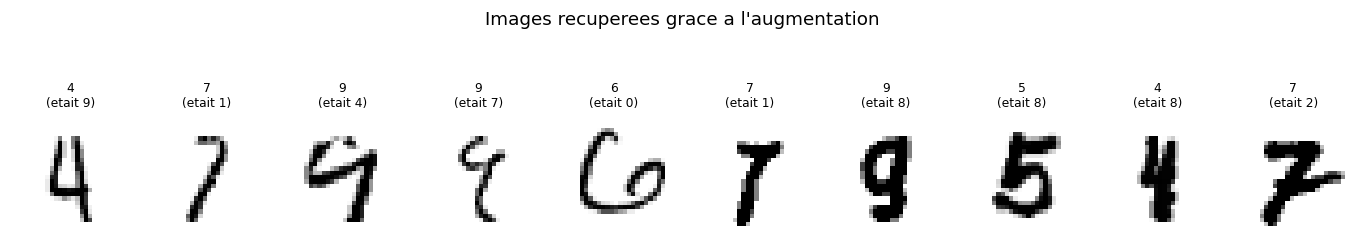

In [31]:
imgs = X_val[recuperees]
vrais = y_val[recuperees]
avant = pred_base[recuperees]

n_show = min(10, len(imgs))
fig, axes = plt.subplots(1, n_show, figsize=(1.25 * n_show, 2.1))
for ax, im, v, a in zip(np.atleast_1d(axes), imgs[:n_show], vrais[:n_show], avant[:n_show]):
    ax.imshow(im.reshape(28, 28), cmap="binary")
    ax.set_title(f"{v}\n(etait {a})", fontsize=8)
    ax.axis("off")
fig.suptitle("Images recuperees grace a l'augmentation", y=1.14)
plt.tight_layout()
plt.show()

Beaucoup de ces chiffres sont **mal centrés** ou **écrits de travers**. C'est la signature de ce
qu'on a appris au modèle : la robustesse à la position.

---
## 11. Bilan

### Les quatre pièges de la data augmentation

| Piège | Conséquence | Parade |
|---|---|---|
| Augmenter **avant** le split | Data leakage : les copies d'une image se retrouvent des deux côtés | Split d'abord, augmenter ensuite (trou 1 puis trou 3) |
| Augmenter la validation ou le test | On mesure la performance sur des images artificielles | Augmenter le training set seulement |
| Mélanger `X` et `y` séparément | Étiquettes désalignées, aucune erreur levée, modèle à 10 % | Une seule permutation (trou 4) |
| Garder du `float64` | 1,6 Go au lieu de 196 Mo | Rester en `uint8` (trou 3) |

### Ce qu'il faut retenir

La data augmentation **n'ajoute pas d'information** : les copies sont déterministes. Elle **injecte
une invariance connue du domaine** que le modèle ne pouvait pas deviner. C'est de la régularisation
au sens du bloc **B13** : on réduit la variance sans toucher au modèle.

Le gain est d'autant plus grand que le modèle était **fragile à la transformation en question**.
Le k-NN, qui compare pixel à pixel, gagne beaucoup. La Random Forest, déjà partiellement robuste,
gagne moins. Un CNN, structurellement invariant par translation, gagnerait encore moins — c'est
tout l'intérêt de son architecture.

### Transposition hors MNIST

La question à se poser pour n'importe quel jeu de données : **quelles transformations laissent
l'étiquette inchangée ?**

- Signal vibratoire d'un banc d'essai : un petit décalage temporel, un léger décalage en fréquence,
  un bruit de mesure réaliste ajouté — la nature du défaut ne change pas.
- Image de contrôle de surface : rotation, symétrie, variation d'éclairage.
- Série de capteurs en vol : fenêtre glissante décalée de quelques échantillons.

La contrainte est toujours la même : la transformation doit être **plausible dans le monde réel**.
Retourner un 6 verticalement donnerait un 9 — l'étiquette changerait, et l'augmentation deviendrait
du bruit étiqueté à tort. C'est pour cela que l'exercice ne retient que les translations.

### Auto-évaluation

Sans rouvrir le notebook :

1. Pourquoi la data augmentation réduit-elle la variance plutôt que le bias ?
2. Pourquoi ne faut-il jamais augmenter le validation set ?
3. Que se passe-t-il si on mélange `X` et `y` avec deux permutations différentes, et pourquoi est-ce
   difficile à détecter ?
4. Pourquoi le k-NN gagne-t-il plus que la Random Forest ?
5. Citez une transformation qui serait **interdite** sur MNIST, et pourquoi.

### Rattachement au carnet

- **B12-3** : réduire la variance sans toucher au bias.
- **B13** : la data augmentation comme régularisation.
- **B13-6** : train / validation / test, et pourquoi le test set reste intact.
- **B1M-3** : data leakage, ici provoqué par un split après augmentation.
- **B11-4** : pourquoi l'ordre compte en stochastic gradient descent.
- **B17-15** : la fragilité du k-NN à la distance, réparée ici.
- **B03-13** : vérifier qu'un gain dépasse la barre d'erreur.